In [11]:
import sys
sys.path.append("..")
import pandas as pd

import matplotlib.pyplot as plt
import statsmodels.api as sm

from src.data import load_brent_spot, load_brent_futures
from src.models import random_walk_forecast, ar1_forecast, historical_mean_forecast
from src.features import log_returns, realised_volatility
from src.backtest import walk_forward
from src.metrics import compare_models_staggered

Test Spot loading

<Axes: xlabel='DATE'>

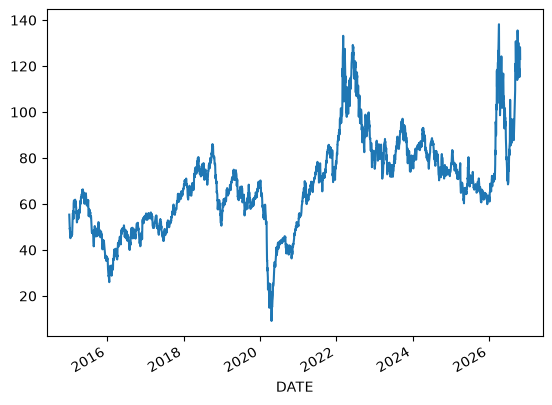

In [12]:
spot = load_brent_spot(start="2015-01-01")
spot.tail()
spot["brent_spot"].plot()

Test Futures loading

<Axes: xlabel='Date'>

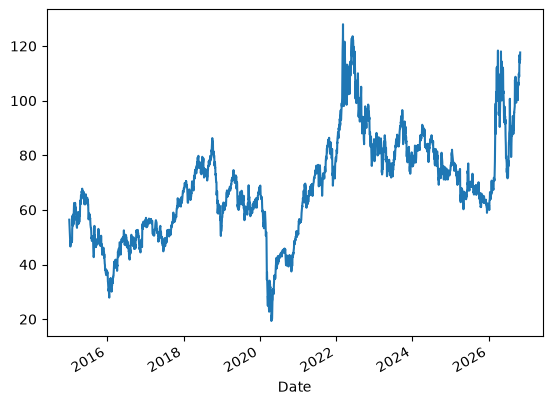

In [13]:
futures = load_brent_futures(start="2015-01-01")
futures.tail()
futures["brent_futures"].plot()

Test log_returns function

DATE
2015-01-02         NaN
2015-01-05   -0.080825
2015-01-06   -0.018973
2015-01-07   -0.021376
2015-01-08    0.007513
                ...   
2026-10-21    0.018488
2026-10-22    0.066098
2026-10-23    0.022942
2026-10-26   -0.001404
2026-10-27   -0.039970
Name: brent_spot, Length: 3001, dtype: float64


<Axes: xlabel='DATE'>

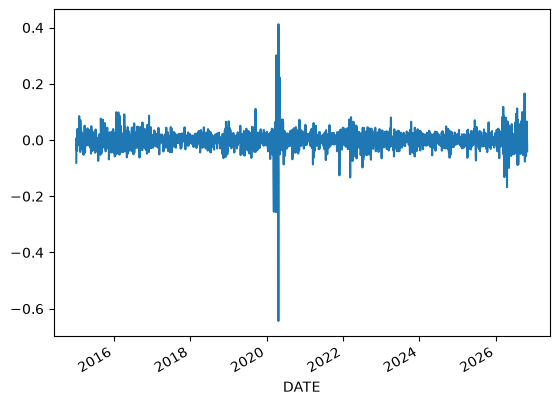

In [14]:
from src.features import log_returns

returns = log_returns(spot)
print(returns)
returns.plot()

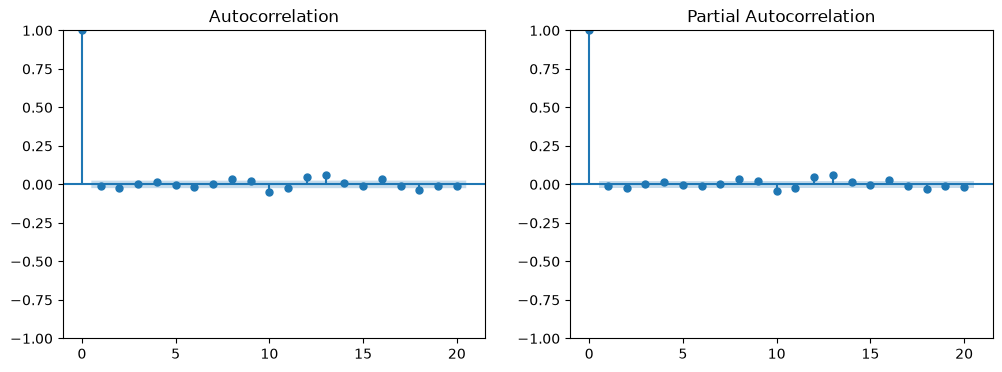

In [15]:
spot = load_brent_spot(start="2000-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sm.graphics.tsa.plot_acf(data["log_return"], lags=20, ax=axes[0])
sm.graphics.tsa.plot_pacf(data["log_return"], lags=20, ax=axes[1])
plt.show()


No significant correlation at any lag.

ACF/PACF are run on log returns (differenced log prices), because log prices are not stationary. An ARMA(p,q) on log returns is the same model as an ARIMA(p,1,q) on log prices. The ACF/PACF are flat, so p = q = 0: ARIMA(0,1,0), which is the random walk.

Next to determine size of training set.

In [16]:
spot = load_brent_spot(start="1987-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

lookback_candidates = [500, 1000, 2000, 3000, 5000, 7000]

summary = []
for lb in lookback_candidates:
    res = walk_forward(
        data,
        horizon=1,
        start_date = "2024-01-01",
        end_date="2025-12-31",
        target_end_date="2025-12-31",
        forecast_funct=ar1_forecast,
        lookback=lb,
    )
    err = res["actual"] - res["forecast"]
    mae = err.abs().mean()
    rmse = (err ** 2).mean() ** 0.5
    mape = (err.abs() / res["actual"]).mean() * 100
    summary.append({"lookback": lb, "MAE": mae, "RMSE": rmse, "MAPE": mape})

summary_df = pd.DataFrame(summary)
summary_df.sort_values("MAPE")

,lookback,MAE,RMSE,MAPE
4,5000,1.018305,1.338738,1.374487
3,3000,1.018965,1.339358,1.375169
5,7000,1.018768,1.339177,1.375218
2,2000,1.019461,1.341158,1.376253
0,500,1.020092,1.339754,1.376422
1,1000,1.020266,1.337531,1.376923


Notice while increasing lookback (training set), the MAPE converges. With more training set, averaged coeff for c and φ (in  c + φ × yesterday's return) both averaged to 0. Therefore forecast is 0 return, which is the same as random walk (tmr price is simply todays price). Will use lookback = 3000 to balance cost of running large training each time.

Test RW, Historical mean (as benchmarks per project brief), and AR1

In [17]:
spot = load_brent_spot(start="2000-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

rw_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31", forecast_funct=random_walk_forecast)
ar1_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31", forecast_funct=ar1_forecast, lookback=3000)
mean_results = walk_forward(data, horizon=1, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31", forecast_funct=historical_mean_forecast, lookback=3000)

vol = realised_volatility(data)

results_dict = {
    "Random Walk": rw_results,
    "AR(1), lb=2000": ar1_results,
    "Historical Mean": mean_results,
}

compare_models_staggered(results_dict)


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,1.017925,1.337748,1.373841,0.005929,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0,0.000000,0.0,504
"AR(1), lb=2000",1.018965,1.339358,1.375169,0.466403,0.445087,0.309237,0.364929,0.477477,0.625984,0.541738,-0.291128,0.286125,-1.017486,-0.617548,1.0,0.339286,213.0,504
Historical Mean,1.018121,1.337821,1.373962,0.501976,0.000000,0.000000,0.000000,0.501976,1.000000,0.668421,0.066021,0.286598,0.230361,-0.263059,1.0,0.000000,0.0,504


Check calendar effect next, if any single day can be used as a dummy variable.

Investigate seasonality/calendar effect

                 mean       std  count
day_of_week                           
0           -0.000981  0.027609   1737
1           -0.000842  0.028669   1838
2            0.000422  0.027383   1857
3            0.001411  0.026693   1869
4            0.000947  0.024490   1815
           mean       std  count
month                           
1      0.000812  0.030280    748
2      0.001043  0.022293    706
3      0.000003  0.033208    769
4      0.001852  0.042553    706
5      0.000269  0.023935    751
6      0.000235  0.022312    777
7      0.001098  0.021535    800
8      0.000379  0.022228    801
9      0.000534  0.025171    777
10    -0.001497  0.025278    802
11    -0.000863  0.024194    754
12    -0.001235  0.025181    725


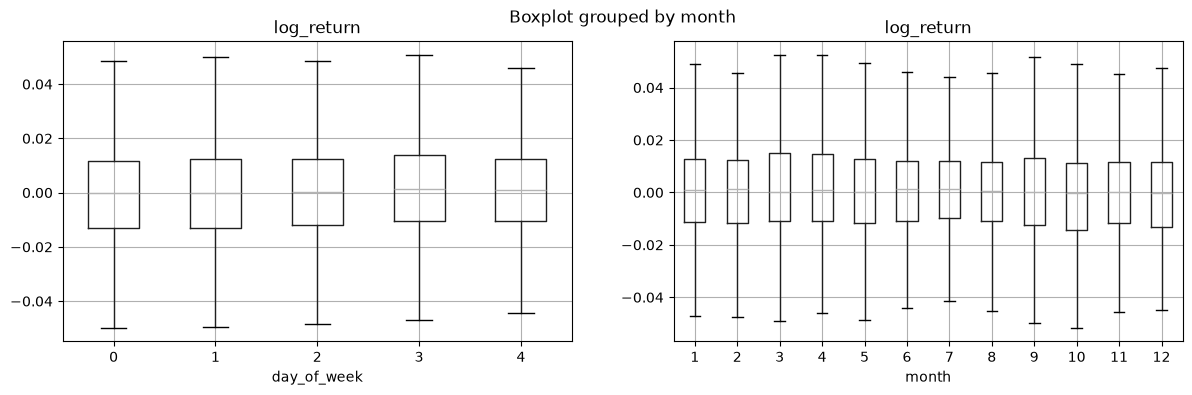

In [18]:
from scipy.stats import kruskal

spot = load_brent_spot(start="1987-01-01")

data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

seasonal = data.copy()
seasonal["day_of_week"] = seasonal.index.dayofweek # (0=Monday, 4=Friday)
seasonal["month"] = seasonal.index.month

print(seasonal.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"])) # do groupby day/month
print(seasonal.groupby("month")["log_return"].agg(["mean", "std", "count"]))

fig, axes = plt.subplots(1,2,figsize = (14, 4))
seasonal.boxplot(column="log_return", by="day_of_week", ax=axes[0], showfliers=False)
seasonal.boxplot(column="log_return", by="month", ax=axes[1], showfliers=False)
plt.show()

In [19]:
groups_days = [g["log_return"].values for _, g in seasonal.groupby("day_of_week")]
groups_months = [g["log_return"].values for _, g in seasonal.groupby("month")]

print("Day of week dist:", kruskal(*groups_days))
print("Months dist:", kruskal(*groups_months))

Day of week dist: KruskalResult(statistic=np.float64(13.951976915853418), pvalue=np.float64(0.0074499133884572705))
Months dist: KruskalResult(statistic=np.float64(14.975902799625505), pvalue=np.float64(0.18360277141200712))


P-value for day of week seem significant since p-val < 0.05. 

In [20]:
# For whole training set
pre_val_period = seasonal[seasonal.index < "2024-01-01"]

groups = [g["log_return"].values for _, g in pre_val_period.groupby("day_of_week")]
print(kruskal(*groups))
print(pre_val_period.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"]))


# Recent years of training set
recent_pre_val_period = seasonal[(seasonal.index >= "2015-01-01") & (seasonal.index < "2024-01-01")]

groups = [g["log_return"].values for _, g in recent_pre_val_period.groupby("day_of_week")]
print(kruskal(*groups))
print(recent_pre_val_period.groupby("day_of_week")["log_return"].agg(["mean", "std", "count"]))




KruskalResult(statistic=np.float64(12.474617678986375), pvalue=np.float64(0.014149734625531584))
                 mean       std  count
day_of_week                           
0           -0.000874  0.027493   1602
1           -0.001003  0.028743   1690
2            0.000548  0.027502   1712
3            0.001160  0.026630   1725
4            0.000948  0.023948   1672
KruskalResult(statistic=np.float64(2.7440294326678334), pvalue=np.float64(0.601532308959124))
                 mean       std  count
day_of_week                           
0           -0.001989  0.030997    434
1           -0.001709  0.040914    462
2            0.001760  0.033333    466
3            0.000819  0.028922    468
4            0.001732  0.026302    456


While the days have different return means, compared to the noise 2%, its a tiny difference. (e.g. Thursday (+0.12%) vs Monday (-ve 0.1%) has difference of < 0.22%, but std devatiation (noise) is ~ 2.7%)

Converted to price: forecast = today's price × exp(predicted return). On a $100 barrel:

Thursday: 100 × exp(0.00116) ≈ $100.12
Tuesday: 100 × exp(−0.001003) ≈ $99.90
Random walk: $100.00
So the dummy moves the forecast by about 10–12 cents.

Our RW MAE is around $1.60. So a dummy variable shifting by 10cents wont greatly reduce our MAE. There no reason to add calendar effect also.

Additionally, if you isolate for recent years only, the p-value > 0.05, and no weekday is significant.



Testing frozen fitting after Oct 1 2026.

In [21]:
import sys
sys.path.append("..")

from src.data import load_brent_spot
from src.features import log_returns
from src.models import random_walk_forecast, ar1_forecast, historical_mean_forecast
from src.backtest import walk_forward
from src.metrics import compare_models_staggered

spot = load_brent_spot(start="1987-01-01")
data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()


test_args = dict(horizon=1, start_date="2026-10-01", end_date="2026-10-23",
                 fit_end_date="2026-09-30", target_end_date="2026-10-23")

test_results = {
    "Random Walk": walk_forward(data, forecast_funct=random_walk_forecast, **test_args),
    "AR(1), lb=5000": walk_forward(data, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    "Historical Mean": walk_forward(data, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
}

compare_models_staggered(test_results)


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days
model,,,,,,,,,,,,,,,,,,
Random Walk,4.067500,6.632445,3.196150,0.0000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,NaN,0.000000,0.0,0.000000,0.0,14
"AR(1), lb=5000",4.062296,6.597416,3.192439,0.4375,0.416667,0.714286,0.526316,0.5,0.222222,0.307692,-1.024868,0.564604,-1.815200,-0.159389,1.0,0.785714,180.0,14
Historical Mean,4.070704,6.630353,3.198904,0.4375,0.437500,1.000000,0.608696,0.0,0.000000,0.000000,-1.245066,0.562743,-2.212497,-0.114918,1.0,1.000000,0.0,14


Adding Endogenous variables to test VAR model.

In [22]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from statsmodels.tsa.api import VAR
from src.data import load_dataset

In [23]:
data = load_dataset()
data.apply(lambda s: s.first_valid_index())   # first date each column has data

brent_spot           1987-05-20
wti                  1987-05-20
usd                  2006-01-03
vix                  1990-01-02
ovx                  2007-05-10
epu                  1987-05-20
sp500                1987-05-20
gpr                  1987-05-20
invt_weekly_change   1987-05-20
dtype: datetime64[us]

USD and OVX start on 2006 and 2007 respectively. dropna therefore makes training pool from 2007.

In [24]:
PRICES = ["brent_spot", "wti", "usd", "sp500"]   # prices -> log returns for stationarity
INDICES = ["vix", "ovx", "epu", "gpr"] 
CHANGES = ["invt_weekly_change"]  # alr in percent -> no need do log diff

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
for col in CHANGES:
    X[col] = data[col]

X = X.dropna()                         # sample now starts when the last variable (OVX) starts
pre = X[X.index < "2024-01-01"]        # test only on data before validation, so no peeking
pre.shape                           

/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


(4197, 9)

In [25]:
band = 2 / np.sqrt(len(pre))
ccm = pd.DataFrame(
    {col: [pre["brent_spot"].corr(pre[col].shift(k)) for k in range(1, 6)] for col in pre.columns},
    index=range(1, 6),
)
ccm.index.name = "lag k"
print(f"significant if |corr| > {band:.3f}")
ccm.round(3)

significant if |corr| > 0.031


,brent_spot,wti,usd,sp500,vix,ovx,epu,gpr,invt_weekly_change
lag k,,,,,,,,,
1,0.063,0.169,0.004,0.088,-0.017,0.015,0.039,-0.014,0.020
2,-0.017,0.067,-0.006,0.009,-0.003,0.025,0.042,-0.009,0.009
3,-0.007,0.086,-0.006,-0.016,0.002,0.026,0.037,-0.011,0.009
4,0.016,0.015,-0.022,0.032,0.005,0.037,0.033,-0.026,0.008
5,-0.010,-0.037,0.007,0.000,0.007,0.036,0.020,-0.026,0.018


See todays brent got some correlation to the lag 1's of WTI and SP500 (and epu boredline). Potentially because US markets close later than london Brent, so Brent only reacts the following day.

CCM only tells us which variable directly influences brent spot today, maybe groups of variables can give us some insight.

In [26]:
pre_var = pre.reset_index(drop=True)   # drop the dates so statsmodels doesn't spam frequency warnings
order = VAR(pre_var).select_order(maxlags=10)
order.summary()

,AIC,BIC,FPE,HQIC
0,-51.96,-51.94,2.725e-23,-51.95
1,-61.08,-60.95,2.966e-27,-61.03
2,-61.27,-61.01,2.469e-27,-61.17
3,-61.40,-61.02*,2.163e-27,-61.26
4,-61.45,-60.94,2.063e-27,-61.27
5,-61.49,-60.86,1.979e-27,-61.27
6,-61.60,-60.85,1.767e-27,-61.34*
7,-61.61,-60.74,1.745e-27,-61.30
8,-61.64,-60.65,1.697e-27,-61.29
9,-61.65,-60.54,1.677e-27,-61.26


order 3 chosen by BIC, but this doesnt mean Brent prices affected by lag 1,2,3 variables. VAR test all variables on the LHS for, so all 8 equations (1 for each variable.) Lag 3 BIC is best for ALL 8 equations. We don't truly know if lag 3 is the best for brent alone. (We will test this later)


Regardless to see lag 3's effect on Brent alone...

brent_t = const + a1·brent_{t-1} + a2·wti_{t-1} + a3·usd_{t-1} + a4·sp500_{t-1}
                + a5·vix_{t-1}   + a6·ovx_{t-1} + a7·epu_{t-1} + a8·gpr_{t-1}
                + a9·brent_{t-2}  + ... + a16·gpr_{t-2}      (same 8 variables, 2 days ago)
                + a17·brent_{t-3} + ... + a24·gpr_{t-3} 


Granger will test: does removing a variable e.g. removing WTI (set a2, a10, a18 = 0), make equation worse at fitting Brent? 
    Null hypo is "this variable DOESN'T help". Hence if p-value is low (< 0.05/8), we reject null hypo.

In [27]:
var_fit = VAR(pre_var).fit(order.bic)
granger = {
    col: var_fit.test_causality(caused="brent_spot", causing=[col], kind="f").pvalue
    for col in pre.columns if col != "brent_spot"
}
pd.Series(granger).sort_values()


wti                   1.587635e-69
sp500                 1.797182e-05
usd                   1.363293e-03
vix                   4.315554e-03
epu                   8.353779e-03
ovx                   8.031709e-02
invt_weekly_change    1.224019e-01
gpr                   8.464177e-01
dtype: float64

WTI, SP500 strong. USD, VIX significant at 5%/8 = 0.006. (Bonferroni correction)

VAR Model

<!-- VAR with endogenous variables from STAGE2 (S2): WTI, SP500, USD, VIX, lag = 2 has the strongest MAPE. Though it only beats RW by < 1%. Since STAGE1 (S1): WTI, SP500, lag = 2, only differs by MAPE of 0.0012. We will pick the simpler model VAR S1, lag=2. -->

In [28]:
import sys
sys.path.append("..")
import itertools
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from src.data import load_dataset
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models_staggered, accuracy_metrics
from src.features import make_lag_features

In [29]:
data = load_dataset()
PRICES = ["brent_spot", "wti", "usd", "sp500"] # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"] # fear/uncertainty indices -> log levels
CHANGES = ["invt_weekly_change"]  # alr in percent -> no need do log diff

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
for col in CHANGES:
    X[col] = data[col]

X = X.dropna()
X.head()

/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,brent_spot,wti,usd,sp500,vix,ovx,epu,gpr,invt_weekly_change
DATE,,,,,,,,,
2007-05-10,0.017639,0.005025,0.001658,-0.014055,2.610070,3.299165,3.145445,4.699531,0.017036
2007-05-11,0.008474,0.008052,0.000557,0.009595,2.561096,3.273743,3.669951,4.612766,0.017036
2007-05-14,0.010379,0.003203,-0.001863,-0.001795,2.636196,3.304319,3.819908,4.598121,0.017036
2007-05-15,0.013273,0.009705,-0.002844,-0.001305,2.639771,3.328268,3.795040,4.528929,0.017036
2007-05-16,0.001348,-0.009385,0.002713,0.008590,2.602690,3.298426,4.407694,4.660464,0.017036


In [30]:
df_var = X.rename(columns={"brent_spot": "log_return"})   # in X, brent_spot is a return, so rename it
df_var["brent_spot"] = data["brent_spot"]                   # add back the Brent PRICE, which walk_forward needs
df_var.head()

,log_return,wti,usd,sp500,vix,ovx,epu,gpr,invt_weekly_change,brent_spot
DATE,,,,,,,,,,
2007-05-10,0.017639,0.005025,0.001658,-0.014055,2.610070,3.299165,3.145445,4.699531,0.017036,64.63
2007-05-11,0.008474,0.008052,0.000557,0.009595,2.561096,3.273743,3.669951,4.612766,0.017036,65.18
2007-05-14,0.010379,0.003203,-0.001863,-0.001795,2.636196,3.304319,3.819908,4.598121,0.017036,65.86
2007-05-15,0.013273,0.009705,-0.002844,-0.001305,2.639771,3.328268,3.795040,4.528929,0.017036,66.74
2007-05-16,0.001348,-0.009385,0.002713,0.008590,2.602690,3.298426,4.407694,4.660464,0.017036,66.83


Hierarchical model selection method in picking VAR variables.

In [31]:
STAGES = {
    "S1": ["log_return", "wti", "sp500"],
    "S2": ["log_return", "wti", "sp500", "usd", "vix"],
    "S3": ["log_return", "wti", "sp500", "usd", "vix", "epu", "ovx", "invt_weekly_change"],
}
val_args = dict(horizon=1, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")

results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
}

for stage, cols in STAGES.items():
    for p in range(1, 6):
        results[f"VAR {stage} p={p}"] = walk_forward(df_var, forecast_funct=var_forecast, cols=cols, lags=p, **val_args)


In [32]:
table = compare_models_staggered(results)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / table.loc["Random Walk", m]) * 100
table.round(4).sort_values("MAPE")

,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,
VAR S2 p=2,0.9953,1.3132,1.3444,0.5573,1.3961,2.2269,1.8335,2.1438
VAR S1 p=2,0.9995,1.3170,1.3498,0.5672,1.4895,1.8080,1.5487,1.7478
VAR S2 p=3,1.0032,1.3309,1.3567,0.5435,1.1688,1.4423,0.5124,1.2496
VAR S1 p=3,1.0077,1.3302,1.3624,0.5336,1.1442,1.0074,0.5631,0.8331
VAR S1 p=1,1.0084,1.3184,1.3626,0.5494,1.3853,0.9364,1.4465,0.8152
VAR S1 p=4,1.0080,1.3304,1.3636,0.5217,0.9593,0.9755,0.5489,0.7444
VAR S2 p=1,1.0092,1.3193,1.3637,0.5356,1.2393,0.8580,1.3824,0.7401
VAR S2 p=4,1.0103,1.3357,1.3659,0.5217,0.9577,0.7518,0.1548,0.5774
VAR S2 p=5,1.0106,1.3369,1.3666,0.5336,1.0650,0.7197,0.0615,0.5287


Forward Selection method in picking VAR variables.

In [33]:
val_args = dict(horizon=1, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")
TIE = 0.002   # a variable must cut MAPE by more than this to be added

rw = walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args)
best_mape = accuracy_metrics(rw)["MAPE"]   # starting point: the random walk
best_lag = None

selected = ["log_return"]
remaining = ["wti", "usd", "sp500", "vix", "ovx", "epu", "gpr", "invt_weekly_change"]
history = []

while remaining:
    jobs = [(var, lag) for var in remaining for lag in range(1, 6)] #pair of each variable and lag
    #Round 1: 8 variables × 5 lags = 40 combinations, e.g. ("wti", 1), ("wti", 2), …, ("invt_weekly_change", 5)
    runs = Parallel(n_jobs=-1)(
        delayed(walk_forward)(df_var, forecast_funct=var_forecast, cols=selected + [var], lags=lag, **val_args)
        for var, lag in jobs
    ) # e.g. ("wti", 2),  means test ["log_return", "wti"] using the last 2 days. Repeat for all pairs (var, lag).
    scores = pd.DataFrame([{"round": len(selected), "var": var, "lag": lag, "MAPE": accuracy_metrics(r)["MAPE"]}
                           for (var, lag), r in zip(jobs, runs)])
    history.append(scores)
    best = scores.loc[scores["MAPE"].idxmin()] # if ("wti", 4) wins, pick "wti" to be added to the model this round, then repeat loop for other variables again.
    print(f"Round {len(selected)}: best add = {best['var']} (lag={best['lag']}), MAPE {best['MAPE']:.4f} vs current {best_mape:.4f}")
    if best["MAPE"] > best_mape - TIE:
        print("Improvement < 0.002, not useful anymore, stop.")
        break
    selected.append(best["var"])
    remaining.remove(best["var"])
    best_mape, best_lag = best["MAPE"], best["lag"]

print("Selected:", selected, "lag =", best_lag) # the best "lag" to use is only determined by the final round.


Round 1: best add = wti (lag=5), MAPE 1.3544 vs current 1.3738
Round 2: best add = sp500 (lag=2), MAPE 1.3498 vs current 1.3544
Round 3: best add = usd (lag=2), MAPE 1.3451 vs current 1.3498
Round 4: best add = invt_weekly_change (lag=2), MAPE 1.3436 vs current 1.3451
Improvement < 0.002, not useful anymore, stop.
Selected: ['log_return', 'wti', 'sp500', 'usd'] lag = 2


In [34]:
all_scores = pd.concat(history)
all_scores.pivot_table(index="var", columns="round", values="MAPE", aggfunc="min").round(4)

# compare_models_staggered(results)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]].round(4)

round,1,2,3,4
var,,,,
epu,1.3941,1.3746,1.3695,1.3635
gpr,1.3772,1.3562,1.3502,1.3461
invt_weekly_change,1.3775,1.3526,1.3477,1.3436
ovx,1.3803,1.3600,1.3546,1.3496
sp500,1.3775,1.3498,NaN,NaN
usd,1.3787,1.3539,1.3451,NaN
vix,1.3778,1.3542,1.3500,1.3444
wti,1.3544,NaN,NaN,NaN


WTI won round 1 (smallest MAPE), hence taken out in round 2 (and added as a perm feature).

SP500 won in round 2, hence taken out in round 3.

USD won in round 3, hence taken out in round 4.

invt_weekly_change won in round but too little difference to improving MAPE.

In [35]:
results = {
    "Random Walk": rw,
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    f"VAR {selected} lag={best_lag}": walk_forward(df_var, forecast_funct=var_forecast, cols=selected, lags=best_lag, **val_args),
}

table = compare_models_staggered(results)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / table.loc["Random Walk", m]) * 100
table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,
"VAR ['log_return', 'wti', 'sp500', 'usd'] lag=2",0.9958,1.3136,1.3451,0.5534,1.2631,2.1695,1.8017,2.0938
Random Walk,1.0179,1.3377,1.3738,0.0059,NaN,0.0000,0.0000,0.0000
Historical Mean,1.0184,1.3384,1.3745,0.4921,-0.2304,-0.0450,-0.0486,-0.0515
AR(1),1.0215,1.3374,1.3784,0.5217,0.4451,-0.3476,0.0227,-0.3343


Best Hierarchical Model Selection method won with +2.14% better MAPE than RW, best Forward Selection (FS) method only had +2.10%. However as the MAPE Gap is small (0.0007), we will use the simpler VAR FS model (4 variables instead of 5). Variables of log_return, wti, sp500, usd with lag 2.

XGBoost

In [36]:
import sys
sys.path.append("..")
import itertools
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from src.data import load_dataset
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models_staggered, accuracy_metrics
from src.features import make_lag_features

In [37]:
data = load_dataset()

PRICES = ["brent_spot", "wti", "usd", "sp500"]  # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]  # fear/uncertainty indices -> log levels
CHANGES = ["invt_weekly_change"]  # alr in percent -> no need do log diff

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
for col in CHANGES:
    X[col] = data[col]
X = X.dropna()
df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]


/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [38]:
FS_VARS = ["log_return", "wti", "sp500", "usd"]
FS_LAG = 2
val_args = dict(horizon=1, start_date="2024-01-01", end_date="2025-12-31", target_end_date="2025-12-31")

feats_fs = make_lag_features(df_var, FS_VARS, lags=FS_LAG)   # same variables and same 4 days as the VAR

# Fine tuning: Iterate through for best params
grid = [dict(n_estimators=n, max_depth=d, min_child_weight=m)
        for n, d, m in itertools.product([50, 200], [1, 2], [1, 100])] # Produce a list of dictionaries, out of the products: [(50,1,1), (50,1,100), (50,2,1)....(200,2,100)]
runs = Parallel(n_jobs=-1)(
    delayed(walk_forward)(df_var, forecast_funct=xgb_forecast, features=feats_fs, **g, **val_args) for g in grid
)

results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **val_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **val_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **val_args),
    f"VAR FS lag={FS_LAG}": walk_forward(df_var, forecast_funct=var_forecast, cols=FS_VARS, lags=FS_LAG, **val_args),
}

xgb_params = {}
for g, r in zip(grid, runs):
    name = f"XGB FS n={g['n_estimators']} d={g['max_depth']} mcw={g['min_child_weight']}"
    results[name] = r
    xgb_params[name] = g


In [39]:
table = compare_models_staggered(results)[["MAE", "RMSE", "MAPE", "directional_accuracy", "sharpe_ratio"]]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / table.loc["Random Walk", m]) * 100
table.round(4).sort_values("MAPE")

,MAE,RMSE,MAPE,directional_accuracy,sharpe_ratio,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,
VAR FS lag=2,0.9958,1.3136,1.3451,0.5534,1.2631,2.1695,1.8017,2.0938
XGB FS n=200 d=1 mcw=100,1.0108,1.3182,1.3649,0.5395,1.2082,0.7026,1.4635,0.6476
XGB FS n=50 d=1 mcw=1,1.0116,1.3287,1.3652,0.5277,1.4515,0.6243,0.6781,0.6289
XGB FS n=50 d=2 mcw=100,1.0112,1.3189,1.3653,0.5198,0.8493,0.6619,1.4064,0.6205
XGB FS n=50 d=1 mcw=100,1.0135,1.3232,1.3689,0.5277,1.5252,0.4317,1.0906,0.3564
XGB FS n=200 d=1 mcw=1,1.0145,1.3309,1.3701,0.5277,0.9074,0.3385,0.5143,0.2749
Random Walk,1.0179,1.3377,1.3738,0.0059,NaN,0.0000,0.0000,0.0000
XGB FS n=200 d=2 mcw=100,1.0185,1.3305,1.3741,0.5099,0.6877,-0.0600,0.5450,-0.0155
Historical Mean,1.0184,1.3384,1.3745,0.4921,-0.2304,-0.0450,-0.0486,-0.0515


Best XGBoost is n = 200 (number of trees), d = 1 (max dept i.e. "yes or no" qns for each tree), mcw = 100 (min child weight i.e. number of training days)

However, doesn't out-perform Forward Selection (FS) VAR (above). Regardless, it is the best XGBoost model, we will keep it for the test set.

DM test (test "model X" against RW, to see if relative performance is real or by luck):

In [40]:
from src.metrics import dm_table

xgb_rows = table[table.index.str.startswith("XGB")]
best_xgb = xgb_rows["MAPE"].idxmin()

final = {name: results[name] for name in
         ["Random Walk", "Historical Mean", "AR(1)", f"VAR FS lag={FS_LAG}", best_xgb]}
dm_table(final).round(4) #-ve DM stat = errors smaller than RW


,DM_stat,p_value,n
Historical Mean,1.2054,0.2286,506.0
AR(1),0.7420,0.4584,506.0
VAR FS lag=2,-1.8275,0.0682,506.0
XGB FS n=200 d=1 mcw=100,-0.8562,0.3923,506.0


FS VAR Diebold-Mariano (DM) stat show both VAR and XGBoost model errors were smaller than RW, however a p-value > 0.05, mean it could be just luck. 

Compare volatility regimes now.

In [41]:
from src.features import garch_volatility
from src.metrics import compare_vol_regimes

xgb_rows = table[table.index.str.startswith("XGB")]
best_xgb = xgb_rows["MAPE"].idxmin()

final = {name: results[name] for name in
         ["Random Walk", "Historical Mean", "AR(1)", f"VAR FS lag={FS_LAG}", best_xgb]}
volatility = garch_volatility(df_var, col="log_return")   # daily GARCH vol, used only to label high/low regimes

compare_vol_regimes(final, volatility)[["MAPE_high_vol", "MAPE_low_vol"]].round(4)

,MAPE_high_vol,MAPE_low_vol
Random Walk,1.5181,1.2296
Historical Mean,1.5182,1.2309
AR(1),1.5236,1.2332
VAR FS lag=2,1.4835,1.2067
XGB FS n=200 d=1 mcw=100,1.5081,1.2217


Every model's error higher during in high-volatility periods in validation dates (2024-01-01 to 2025-12-31).
VAR's edge shows in both periods: 2.28% better than the RW when volatility is high, and 1.86% better in calm periods.

(1.5181 − 1.4835) / 1.5181 = 2.28%

(1.2296 − 1.2067) / 1.2296 = 1.86%

Nonetheless, we proceed with the 2 selected models (and baselines RW, HM and AR(1)) on the test set: 
- VAR FS lag=2: (WTI, S&P 500, USD as endogenous variables, chosen by forward selection, with lag of 2). Best model: MAPE 1.3451 vs the random walk's 1.3738 (+2.09%).
- XGB FS n_estimators=200 max_depth=1 min_child_weight=100 (same variables and same 2 days as the VAR). Best ML model: MAPE 1.3649 (+0.65%).

Both beat the random walk on MAPE, but not significantly at 5% (Diebold-Mariano on MAPE: VAR p = 0.07, XGB p = 0.39).

Run of test set.

In [42]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from src.data import load_dataset
from src.features import make_lag_features
from src.backtest import walk_forward
from src.models import random_walk_forecast, historical_mean_forecast, ar1_forecast, var_forecast, xgb_forecast
from src.metrics import compare_models_staggered

data = load_dataset()

PRICES = ["brent_spot", "wti", "usd", "sp500"]  # prices -> log returns
INDICES = ["vix", "ovx", "epu", "gpr"]  # fear/uncertainty indices -> log levels
CHANGES = ["invt_weekly_change"]  # alr in percent -> no need do log diff

X = pd.DataFrame(index=data.index)
for col in PRICES:
    X[col] = np.log(data[col]).diff()
for col in INDICES:
    X[col] = np.log(data[col])
for col in CHANGES:
    X[col] = data[col]
X = X.dropna()
df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]

FS_VARS = ["log_return", "wti", "sp500", "usd"]
FS_LAG = 2
feats_fs = make_lag_features(df_var, FS_VARS, lags=FS_LAG)

/Users/airrehn/codebase/oil-trading-5210/venv/lib/python3.11/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [43]:
test_args = dict(horizon=1, start_date="2026-10-01", end_date="2026-10-23",
                 fit_end_date="2026-09-30", target_end_date="2026-10-23")

test_results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    f"VAR FS lag={FS_LAG}": walk_forward(df_var, forecast_funct=var_forecast, cols=FS_VARS, lags=FS_LAG, **test_args),
    best_xgb: walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_fs, **xgb_params[best_xgb], **test_args),
}


# For excel


In [44]:
table = compare_models_staggered(test_results)
rw = table.loc["Random Walk"]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / rw[m]) * 100   # positive = better than random walk
table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,...,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,,,,,,,,,,,,,,
Random Walk,4.0675,6.6324,3.1962,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,NaN,0.0000,0.0,0.0000,0.0,14,0.0000,0.0000,0.0000
Historical Mean,4.0751,6.6276,3.2026,0.4375,0.4375,1.0000,0.6087,0.0000,0.0000,0.0000,...,0.5627,-2.2125,-0.1149,1.0,1.0000,0.0,14,-0.1858,0.0726,-0.2032
AR(1),4.1686,6.7673,3.2763,0.3750,0.3636,0.5714,0.4444,0.4000,0.2222,0.2857,...,0.5538,-3.6036,-0.1355,1.0,0.7143,324.0,14,-2.4849,-2.0338,-2.5084
XGB FS n=200 d=1 mcw=100,4.2448,6.6632,3.3465,0.4375,0.4000,0.5714,0.4706,0.5000,0.3333,0.4000,...,0.5643,-1.9325,-0.1361,1.0,0.6429,252.0,14,-4.3598,-0.4635,-4.7031
VAR FS lag=2,4.7367,6.8056,3.7492,0.3750,0.3333,0.4286,0.3750,0.4286,0.3333,0.3750,...,0.5620,-2.3360,-0.1454,1.0,0.5714,252.0,14,-16.4522,-2.6101,-17.3046


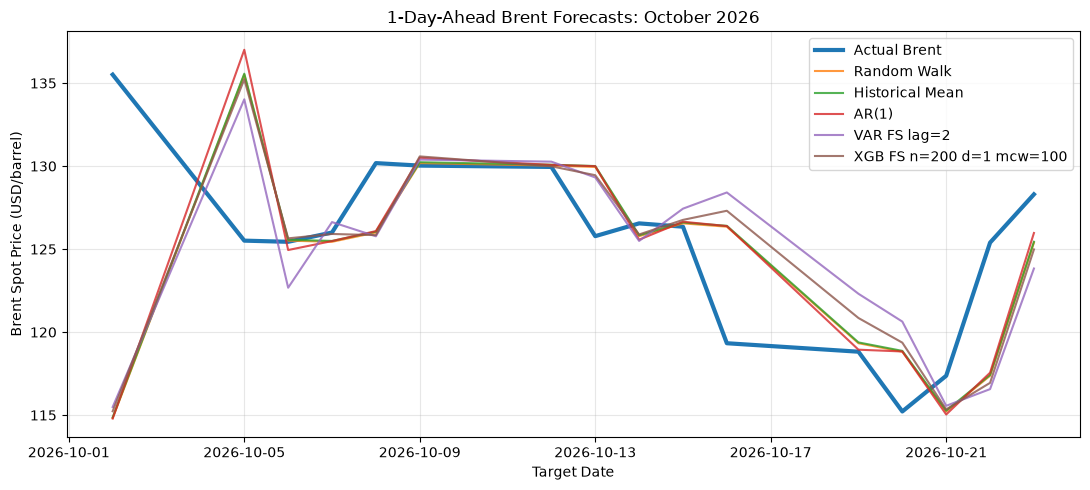

In [ ]:
from src.metrics import compare_models_staggered, plot_forecasts   # bring both functions in

plot_forecasts(test_results, "1-Day-Ahead Brent Forecasts: October 2026")   # draw the chart


In [50]:
test_args = dict(horizon=1, start_date="2026-01-01", end_date="2026-09-30",
                 fit_end_date="2026-09-30", target_end_date="2026-09-30")

test_results = {
    "Random Walk": walk_forward(df_var, forecast_funct=random_walk_forecast, **test_args),
    "Historical Mean": walk_forward(df_var, forecast_funct=historical_mean_forecast, lookback=3000, **test_args),
    "AR(1)": walk_forward(df_var, forecast_funct=ar1_forecast, lookback=3000, **test_args),
    f"VAR FS lag={FS_LAG}": walk_forward(df_var, forecast_funct=var_forecast, cols=FS_VARS, lags=FS_LAG, **test_args),
    best_xgb: walk_forward(df_var, forecast_funct=xgb_forecast, features=feats_fs, **xgb_params[best_xgb], **test_args),
}
# For slides


In [51]:
table = compare_models_staggered(test_results)
rw = table.loc["Random Walk"]
for m in ["MAE", "RMSE", "MAPE"]:
    table[f"{m}_vs_RW_%"] = (1 - table[m] / rw[m]) * 100   # positive = better than random walk
table.round(4).sort_values("MAPE")


,MAE,RMSE,MAPE,directional_accuracy,precision_up,recall_up,f1_up,precision_down,recall_down,f1_down,...,annualized_vol,sharpe_ratio,max_drawdown,avg_gross_exposure,pct_time_net_long,annual_turnover,n_days,MAE_vs_RW_%,RMSE_vs_RW_%,MAPE_vs_RW_%
model,,,,,,,,,,,,,,,,,,,,,
Historical Mean,3.1864,4.4360,3.2560,0.5426,0.5426,1.0000,0.7034,0.0000,0.0000,0.0000,...,0.6896,1.5102,-0.5042,1.0,1.0000,0.0000,186,0.0324,-0.0010,0.0179
Random Walk,3.1874,4.4360,3.2566,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.0000,NaN,0.0000,0.0,0.0000,0.0000,186,0.0000,0.0000,0.0000
AR(1),3.1987,4.4647,3.2677,0.5213,0.5556,0.5882,0.5714,0.4750,0.4419,0.4578,...,0.6918,0.7501,-0.4845,1.0,0.5753,238.4516,186,-0.3554,-0.6472,-0.3423
VAR FS lag=2,3.1973,4.4988,3.2743,0.5000,0.5392,0.5392,0.5392,0.4535,0.4535,0.4535,...,0.6925,-0.3222,-0.5332,1.0,0.5430,214.0645,186,-0.3102,-1.4165,-0.5452
XGB FS n=200 d=1 mcw=100,3.2343,4.4981,3.3073,0.5213,0.5536,0.6078,0.5794,0.4737,0.4186,0.4444,...,0.6899,1.3864,-0.2920,1.0,0.5968,241.1613,186,-1.4730,-1.4003,-1.5580


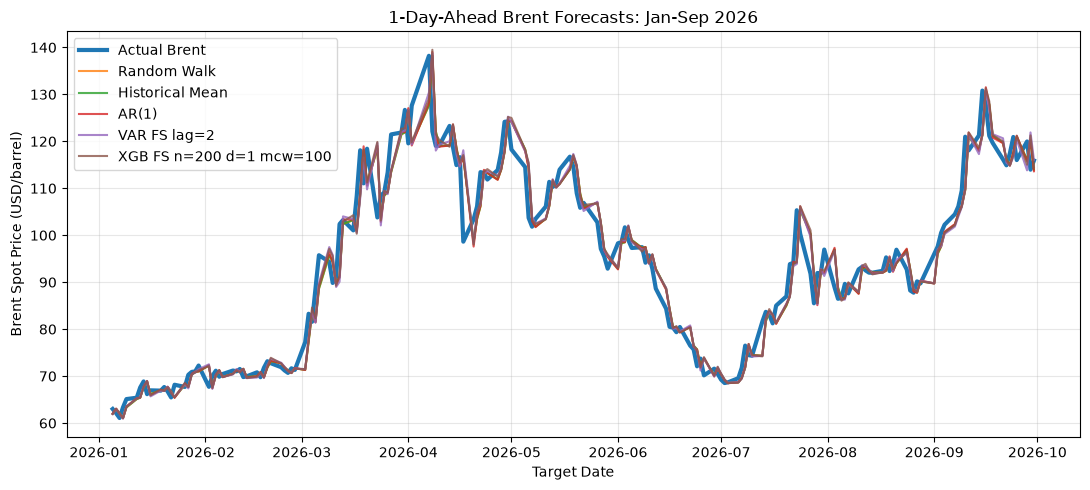

In [52]:
plot_forecasts(test_results, "1-Day-Ahead Brent Forecasts: Jan-Sep 2026")

In [53]:
from src.features import garch_volatility

volatility = garch_volatility(df_var, col="log_return")            # daily GARCH vol for every day
val_median = volatility["2024-01-01":"2025-12-30"].median()       # same cut-off as the validation regime split
test_vol = volatility.reindex(test_results["Random Walk"]["origin_date"])  # extract vol on each day of the test set
test_vol_mean = volatility.reindex(test_results["Random Walk"]["origin_date"]).mean()   # then take mean

print(f"Validation median vol: {val_median:.2%}")
print(f"Test average vol:   {test_vol_mean:.2%}")
print(f"Test days in high-vol regime: {(test_vol >= val_median).sum()} of {len(test_vol)}") # count how many test days' volatility is above the median from 2024-01-01 to 2025-12-30


Validation median vol: 1.78%
Test average vol:   4.01%
Test days in high-vol regime: 183 of 188


Test set (Jan–Sep 2026) is a high-volatility period: 183 of 188 days are above the validation median volatility (average 4.01% vs 1.78%). In validation, VAR was 2.28% better than the RW on high-volatility days, but those days averaged 2.19% volatility, about half the test period's 4.01%, so that edge may not carry over.